# 07 — Time-varying currency risk prices: USD and EUR

Audit the currency-price conditioners first, then allow **both FX risk prices** to depend on lagged
information. The world price remains time-varying as in notebook 06; US and Hungarian local prices
remain time-constant. All coefficients and nuisance parameters are jointly re-estimated.

Run `06_time_varying_world.ipynb`, then **Run All** here in the existing Miniconda **base** kernel.
Keep the same frozen sample: **321 months, 2000-01 to 2026-09**, by default. No downloads, new
API calls or edits to the frozen dataset are made. Raw pre-sample observations preserve the first month
when constructing changes in the lagged annual inflation gaps.

In [1]:
# Adjustable settings. Never fetch data or change the frozen snapshot in this notebook.
SNAPSHOT = "data/fixed_2026-11-13/from_2000-01"
ANALYSIS_START = None
ANALYSIS_END = None
FX_VAR_LAGS = 6  # Must match notebook 06.
HUF_INFLATION_FORM = "change"  # "change" or "level"; original levels remain audited.
OTHER_INFLATION_FORM = "level"  # US/euro-area gap is less persistent in this sample.
INCLUDE_HUF_REGIME = True  # Known full-month floating indicator; HUF price only.
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
SE_STEP_TOL = 0.01  # Withhold uncertainty if risk-price SEs move by more than 1% at half Hessian step.
COVARIANCE_MODELS = ["scalar", "diagonal"]
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.75)]  # alpha, beta
MAX_ITER = 1600
TEST_LAGS = 12
REUSE_FITS = True  # False forces re-estimation; model code and settings enter the cache key.
MODEL_VERSION = "time_varying_currency_v1"

from pathlib import Path
from io import BytesIO
import hashlib
import importlib.metadata
import json
import os
import platform
import sys

ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax
from scipy.stats import norm, chi2
from packaging.version import Version
sm_version = importlib.metadata.version("statsmodels")
if Version(sm_version) < Version("0.15.0"):
    raise RuntimeError("Run %pip install --upgrade statsmodels==0.15.0, then Restart Kernel and Run All.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != sm_version:
    raise RuntimeError("statsmodels was updated. Restart Kernel and Run All to discard old imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
from IPython.display import display, Markdown

versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]}
print("Python:", sys.executable)
print("Packages:", versions)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
source = ROOT / SNAPSHOT
manifest = json.loads((source / "manifest.json").read_text())
raw = (source / "dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest() != manifest["exports"]["dataset.csv"]:
    raise ValueError("The frozen dataset is not sealed or its checksum differs.")
data = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
data.index = pd.PeriodIndex(data.index, freq="M", name="month")
if not data.index.equals(pd.period_range(data.index[0], data.index[-1], freq="M")):
    raise ValueError("Missing or duplicate months.")
data = data.loc[ANALYSIS_START:ANALYSIS_END].copy()
if len(data) < max(120, 5 * TEST_LAGS) or not 2 <= TEST_LAGS <= 24:
    raise ValueError("Use at least 120 months and TEST_LAGS from 2 to 24 for this initial fit.")

if not isinstance(FX_VAR_LAGS, int) or not 0 <= FX_VAR_LAGS <= 12:
    raise ValueError("FX_VAR_LAGS must be an integer from 0 to 12.")
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS)) != len(COVARIANCE_MODELS) or any(
        c not in ["scalar", "diagonal"] for c in COVARIANCE_MODELS):
    raise ValueError("Choose scalar, diagonal, or both covariance models without duplicates.")
if any(a <= 0 or b <= 0 or a+b >= 1 for a,b in START_DYNAMICS):
    raise ValueError("Starting alpha/beta must be positive and sum to less than one.")
# Estimate scalar first if both are requested, to initialise the nested diagonal model.
COVARIANCE_MODELS = [c for c in ["scalar", "diagonal"] if c in COVARIANCE_MODELS]
ASSETS = ["World", "US", "Hungary", "HUF FX", "Other FX"]
FX_NAMES = {"USD": ["HUF", "EUR"], "EUR": ["HUF", "USD"]}
fx_raw = (source / "raw" / "ecb_fx.csv").read_bytes()
fx_source_sha256 = hashlib.sha256(fx_raw).hexdigest()
if fx_source_sha256 != manifest["sources"]["ecb_fx.csv"]["sha256"]:
    raise ValueError("Frozen ECB source checksum differs.")
ecb = pd.read_csv(BytesIO(fx_raw), usecols=["TIME_PERIOD", "CURRENCY", "OBS_VALUE"], float_precision="round_trip")
ecb["TIME_PERIOD"] = pd.to_datetime(ecb["TIME_PERIOD"])
ecb["OBS_VALUE"] = pd.to_numeric(ecb["OBS_VALUE"], errors="raise")
ecb = ecb.pivot(index="TIME_PERIOD", columns="CURRENCY", values="OBS_VALUE").sort_index()
ecb = ecb.groupby(ecb.index.to_period("M")).last()
fx_usd = pd.DataFrame({"HUF": -np.log(ecb["HUF"] / ecb["USD"]).diff(),
                       "EUR": np.log(ecb["USD"]).diff()}) * 100
fx_eur = pd.DataFrame({"HUF": fx_usd["HUF"] - fx_usd["EUR"], "USD": -fx_usd["EUR"]})
np.testing.assert_allclose(fx_usd.loc[data.index].to_numpy(),
                          data[["fx_huf_usd", "fx_eur_usd"]].to_numpy()*100, atol=1e-11, rtol=0)
np.testing.assert_allclose(fx_eur.loc[data.index, "HUF"], data["fx_huf_eur"]*100, atol=1e-11, rtol=0)
samples, designs, scales_by_currency = {}, {}, {}
for currency, fx in [("USD", fx_usd), ("EUR", fx_eur)]:
    equities = data[[f"rx_{a}_{currency.lower()}" for a in ["world", "us", "hu"]]].to_numpy()*100
    y = np.c_[equities, fx.loc[data.index].to_numpy()]
    scales = y.std(axis=0, ddof=1)
    lagged = [(fx/scales[3:]).shift(lag).loc[data.index].to_numpy() for lag in range(1, FX_VAR_LAGS+1)]
    x = np.c_[np.ones(len(data)), np.concatenate(lagged, axis=1)] if lagged else np.ones((len(data),1))
    if not np.isfinite(y).all() or not np.isfinite(x).all() or not (scales>0).all():
        raise ValueError("Missing FX history or non-finite data. Reduce FX_VAR_LAGS or move ANALYSIS_START later.")
    if np.linalg.matrix_rank(x) != x.shape[1]:
        raise ValueError("FX mean design is rank deficient.")
    samples[currency], designs[currency], scales_by_currency[currency] = y, x, scales
# Check the observed USD-to-EUR transformation, including the two different cash proxies.
transform = np.eye(5)
transform[:3,4], transform[3,4], transform[4,4] = -1., -1., -1.
converted = samples["USD"] @ transform.T
converted[:,:3] += ((data["rf_usd"]-data["rf_eur_proxy"])*100).to_numpy()[:,None]
np.testing.assert_allclose(converted, samples["EUR"], atol=1e-10, rtol=0)


CANDIDATES=["short_rate_change_lag1_pp","term_spread_change_lag1_pp","credit_spread_lag1_pp"]
if not WORLD_INSTRUMENTS or len(set(WORLD_INSTRUMENTS))!=len(WORLD_INSTRUMENTS) or any(c not in CANDIDATES for c in WORLD_INSTRUMENTS):
    raise ValueError("Use a unique, nonempty subset of the global instrument set from notebook 06.")
if HUF_INFLATION_FORM not in ["level","change"] or OTHER_INFLATION_FORM not in ["level","change"] or not isinstance(INCLUDE_HUF_REGIME,bool):
    raise ValueError("Choose level/change inflation forms and a Boolean regime setting.")
world_id=hashlib.sha256(json.dumps(WORLD_INSTRUMENTS).encode()).hexdigest()[:8]
BASELINE=ROOT/"output"/"06_time_varying_world"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/f"var{FX_VAR_LAGS}_z{world_id}"
spec={"world":WORLD_INSTRUMENTS,"HUF_inflation":HUF_INFLATION_FORM,"other_inflation":OTHER_INFLATION_FORM,"HUF_regime":INCLUDE_HUF_REGIME}
spec_id=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:8]
OUT=ROOT/"output"/"07_time_varying_currency"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/f"var{FX_VAR_LAGS}_x{spec_id}"
OUT.mkdir(parents=True,exist_ok=True)
display(pd.DataFrame({"first":[str(data.index[0])],"last":[str(data.index[-1])],"months":[len(data)],
                      "FX_factors":[2],"HUF_inflation_form":[HUF_INFLATION_FORM],"other_inflation_form":[OTHER_INFLATION_FORM]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,FX_factors,HUF_inflation_form,other_inflation_form
0,2000-01,2026-09,321,2,change,level


## 1. Check the instruments and their timing

Reuse the three global financial predictors audited in notebook 06. Rebuild them from sealed FRED
data, and reconstruct annual US CPI / Hungarian and euro-area HICP inflation from the original
frozen raw files. Match the two-month-lagged panel gaps and quality flag exactly.

Let $g_{H,t}=(\pi^{annual}_{investor}-\pi^{annual}_{HU})_{t-2}$ and
$g_{O,t}=(\pi^{annual}_{investor}-\pi^{annual}_{other})_{t-2}$. USD investors use US−HU and US−EA;
EUR investors use EA−HU and EA−US. The annual inflation rates are in percentage points.

| Price function | Conditioning information, plus an intercept |
|---|---|
| World | Same three lagged global financial variables as notebook 06 |
| HUF FX | Global variables + change in the lagged annual inflation gap + Hungary floating-regime indicator |
| EUR FX (USD investor) / USD FX (EUR investor) | Global variables + lagged US/EA inflation-gap level, with the investor-specific sign |

HUF inflation-gap **levels** have AR(1) near 0.98; ADF does not reject a unit root, while KPSS does
not reject level stationarity. The evidence is inconclusive. The default uses their **monthly changes**
as a conservative exploratory conditioner, rather than claiming the levels are stationary. The US/EA
level gap is less persistent and rejects a unit root in the initial audit. Both forms stay audited and
adjustable; changing settings creates a separate output folder. They are not selected for pricing p-values.

The regime indicator starts in **March 2008**, the first full month after the
[MNB's 26 February regime change](https://www.mnb.hu/en/monetary-policy/monetary-policy-framework/exchange-rate-regime).
It is a predetermined Hungary-specific break indicator, not an estimated causal effect. It does not
enter the other-currency price. No unit-root test is applied to this deterministic dummy.

The existing one-month carry of an unavailable **US annual inflation rate** is preserved exactly.
Its flag affects December 2025 in level conditioners and December 2025 / January 2026 in changes.
No extra carry or interpolation is introduced. US CPI and European HICP are different index concepts;
these remain downloaded historical vintages, with approximate publication lags. No dividend yield is added.

In [2]:
# Reconstruct global and inflation conditioners from sealed raw files, including pre-sample history.
fred_raw=(source/"raw"/"fred.csv").read_bytes()
hicp_raw=(source/"raw"/"eurostat_hicp.json").read_bytes()
fred_sha256=hashlib.sha256(fred_raw).hexdigest()
hicp_sha256=hashlib.sha256(hicp_raw).hexdigest()
for name,digest in [("fred.csv",fred_sha256),("eurostat_hicp.json",hicp_sha256)]:
    if digest!=manifest["sources"][name]["sha256"]: raise ValueError(f"Frozen {name} checksum differs.")
fred=pd.read_csv(BytesIO(fred_raw),index_col=0,na_values=".",float_precision="round_trip")
fred.index=pd.PeriodIndex(fred.index,freq="M")
if not fred.index.is_unique: raise ValueError("Duplicate FRED months.")
fred=fred.reindex(pd.period_range(fred.index.min(),fred.index.max(),freq="M"))
rebuilt_global=pd.DataFrame({CANDIDATES[0]:fred["TB3MS"].diff().shift(1),
                            CANDIDATES[1]:(fred["GS10"]-fred["TB3MS"]).diff().shift(1),
                            CANDIDATES[2]:(fred["BAA"]-fred["AAA"]).shift(1)}).loc[data.index]
np.testing.assert_allclose(rebuilt_global.to_numpy(),data[CANDIDATES].to_numpy(),atol=1e-12,rtol=0)
hj=json.loads(hicp_raw)
if hj["id"]!=["freq","unit","coicop18","geo","time"] or hj["size"][:3]!=[1,1,1]:
    raise ValueError("Unexpected frozen HICP layout.")
values=np.full(int(np.prod(hj["size"])),np.nan)
for position,value in hj["value"].items(): values[int(position)]=value
values=values.reshape(hj["size"])[0,0,0]
cat=hj["dimension"]
hicp_dates=sorted(cat["time"]["category"]["index"],key=cat["time"]["category"]["index"].get)
hicp=pd.DataFrame({c:values[cat["geo"]["category"]["index"][c]] for c in ["HU","EA"]},
                  index=pd.PeriodIndex(hicp_dates,freq="M"))
full_index=pd.period_range(max(hicp.index.min(),fred.index.min()),data.index.max(),freq="M")
price_indices_data=pd.concat([fred["CPIAUCNS"].rename("US"),hicp],axis=1).reindex(full_index)
annual=price_indices_data.pct_change(12,fill_method=None)*100
carry_limit=int(manifest["max_us_inflation_carry_months"])
us_for_z=annual["US"].ffill(limit=carry_limit) if carry_limit else annual["US"]
carry=(annual["US"].isna() & us_for_z.notna()).shift(2,fill_value=False)
gap_levels=pd.DataFrame({"US_HU":us_for_z-annual["HU"],"EA_HU":annual["EA"]-annual["HU"],
                         "US_EA":us_for_z-annual["EA"]}).shift(2)
gap_changes=gap_levels.diff()
np.testing.assert_allclose(gap_levels.loc[data.index,["US_HU","EA_HU"]].to_numpy(),
                          data[["inflation_gap_usd_lag2_pp","inflation_gap_eur_lag2_pp"]].to_numpy(),atol=1e-12,rtol=0)
np.testing.assert_allclose(gap_levels.loc[data.index,"US_EA"],
                          data["inflation_gap_usd_lag2_pp"]-data["inflation_gap_eur_lag2_pp"],atol=1e-12,rtol=0)
np.testing.assert_array_equal(carry.loc[data.index].astype(int),data["flag_us_inflation_carried_lag2"].astype(int))
regime=pd.Series((data.index>=pd.Period("2008-03",freq="M")).astype(int),index=data.index,name="floating_regime_known")
np.testing.assert_array_equal(regime,data["floating_regime_known"].astype(int))

# Audit every candidate before choosing any pricing fit. Opposite-sign US/EA gaps have identical tests.
def stationarity_row(values):
    a=adfuller(values.to_numpy(),maxlag=12,regression="c",autolag="AIC",result_object=False)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always",InterpolationWarning)
        k=kpss(values.to_numpy(),regression="c",nlags="auto",result_object=False)
    bound=(">=" if k[1]>=.10 else "<=") if any(issubclass(w.category,InterpolationWarning) for w in caught) else ""
    return {"n":len(values),"AR1":values.autocorr(),"ADF_p":a[1],"ADF_lags":a[2],
            "KPSS_p_report":f"{bound}{k[1]:.2f}","mean_pp":values.mean(),"sd_pp":values.std(ddof=1)}
audit_rows=[]
for name in CANDIDATES:
    audit_rows.append({"variable":name,"form":"global",**stationarity_row(data[name])})
for name in gap_levels:
    for form,frame in [("level",gap_levels),("change",gap_changes)]:
        audit_rows.append({"variable":name,"form":form,**stationarity_row(frame.loc[data.index,name])})
instrument_audit=pd.DataFrame(audit_rows).set_index(["variable","form"])
price_designs,feature_frames,normalizer_rows,design_rows={},{},[],[]
quality_rows=[]
for currency in ["USD","EUR"]:
    huf_gap="US_HU" if currency=="USD" else "EA_HU"
    huf_source=gap_changes if HUF_INFLATION_FORM=="change" else gap_levels
    other_source=gap_changes if OTHER_INFLATION_FORM=="change" else gap_levels
    huf=data[WORLD_INSTRUMENTS].copy()
    huf[f"HUF_inflation_gap_{HUF_INFLATION_FORM}_lag2_pp"]=huf_source.loc[data.index,huf_gap]
    if INCLUDE_HUF_REGIME: huf["floating_regime_known"]=regime
    other=data[WORLD_INSTRUMENTS].copy()
    other[f"other_inflation_gap_{OTHER_INFLATION_FORM}_lag2_pp"]=(1 if currency=="USD" else -1)*other_source.loc[data.index,"US_EA"]
    frames={"W":data[WORLD_INSTRUMENTS].copy(),"H":huf,"O":other}
    price_designs[currency],feature_frames[currency]={},frames
    for label,frame in frames.items():
        centre,spread=frame.mean(),frame.std(ddof=1)
        if not np.isfinite(frame.to_numpy()).all() or not spread.gt(0).all():
            raise ValueError("Missing/constant price instrument; inspect the sample or disable a constant regime indicator.")
        design=np.c_[np.ones(len(data)),((frame-centre)/spread).to_numpy()]
        if np.linalg.matrix_rank(design)!=design.shape[1]: raise ValueError("Price design is rank deficient.")
        price_designs[currency][label]=design
        vifs=[variance_inflation_factor(design,j+1) for j in range(frame.shape[1])]
        design_rows.append({"perspective":currency,"price":label,"n":len(data),"columns":design.shape[1],
                            "rank":np.linalg.matrix_rank(design),"condition":np.linalg.cond(design),"max_VIF":max(vifs)})
        for j,name in enumerate(frame.columns):
            normalizer_rows.append({"perspective":currency,"price":label,"instrument":name,
                                   "mean":centre[name],"sd":spread[name],"VIF":vifs[j]})
    huf_flag=carry | carry.shift(1,fill_value=False) if HUF_INFLATION_FORM=="change" else carry
    other_flag=carry | carry.shift(1,fill_value=False) if OTHER_INFLATION_FORM=="change" else carry
    for month in data.index:
        quality_rows.append({"perspective":currency,"month":str(month),
                             "HUF_inflation_uses_carried_US_rate":int(huf_flag.loc[month] if currency=="USD" else False),
                             "other_inflation_uses_carried_US_rate":int(other_flag.loc[month])})
design_audit=pd.DataFrame(design_rows).set_index(["perspective","price"])
normalizers=pd.DataFrame(normalizer_rows).set_index(["perspective","price","instrument"])
quality=pd.DataFrame(quality_rows).set_index(["perspective","month"])
regime_counts=regime.value_counts().sort_index().rename_axis("floating_regime").to_frame("months")
display(instrument_audit.round(5))
display(design_audit.round(4))
display(regime_counts)
display(quality.loc[quality.any(axis=1)])
print(f"Conditioning forms: HUF={HUF_INFLATION_FORM}, other FX={OTHER_INFLATION_FORM}; no rows dropped.")

n      AR1    ADF_p  ADF_lags  \
variable                   form                                      
short_rate_change_lag1_pp  global  321  0.54897  0.00000         2   
term_spread_change_lag1_pp global  321  0.30734  0.00000         2   
credit_spread_lag1_pp      global  321  0.95803  0.00048         5   
US_HU                      level   321  0.97860  0.10761        12   
                           change  321  0.55157  0.00000        12   
EA_HU                      level   321  0.97782  0.10881        12   
                           change  321  0.42018  0.00000        12   
US_EA                      level   321  0.92631  0.00870        12   
                           change  321  0.30352  0.00000        11   

                                  KPSS_p_report  mean_pp    sd_pp  
variable                   form                                    
short_rate_change_lag1_pp  global        >=0.10 -0.00421  0.18770  
term_spread_change_lag1_pp global        >=0.10 -0.00000  0.23599  
credit_spread_lag1_pp      global        >=0.10  0.99056  0.39931  
US_HU                      level         >=0.10 -2.60055  3.73889  
                           change        >=0.10  0.03013  0.77161  
EA_HU                      level         >=0.10 -3.05221  3.24840  
                           change        >=0.10  0.03271  0.68137  
US_EA                      level         >=0.10  0.45166  0.96130  
                           change        >=0.10 -0.00258  0.36890

n  columns  rank  condition  max_VIF
perspective price                                        
USD         W      321        4     4     1.7919   1.3805
            H      321        6     6     1.8742   1.4332
            O      321        5     5     1.9049   1.4318
EUR         W      321        4     4     1.7919   1.3805
            H      321        6     6     1.8753   1.4327
            O      321        5     5     1.9049   1.4318

,months
floating_regime,
0,98
1,223


HUF_inflation_uses_carried_US_rate  \
perspective month                                         
USD         2025-12                                   1   
            2026-01                                   1   
EUR         2025-12                                   0   

                     other_inflation_uses_carried_US_rate  
perspective month                                          
USD         2025-12                                     1  
            2026-01                                     0  
EUR         2025-12                                     1

Conditioning forms: HUF=change, other FX=level; no rows dropped.


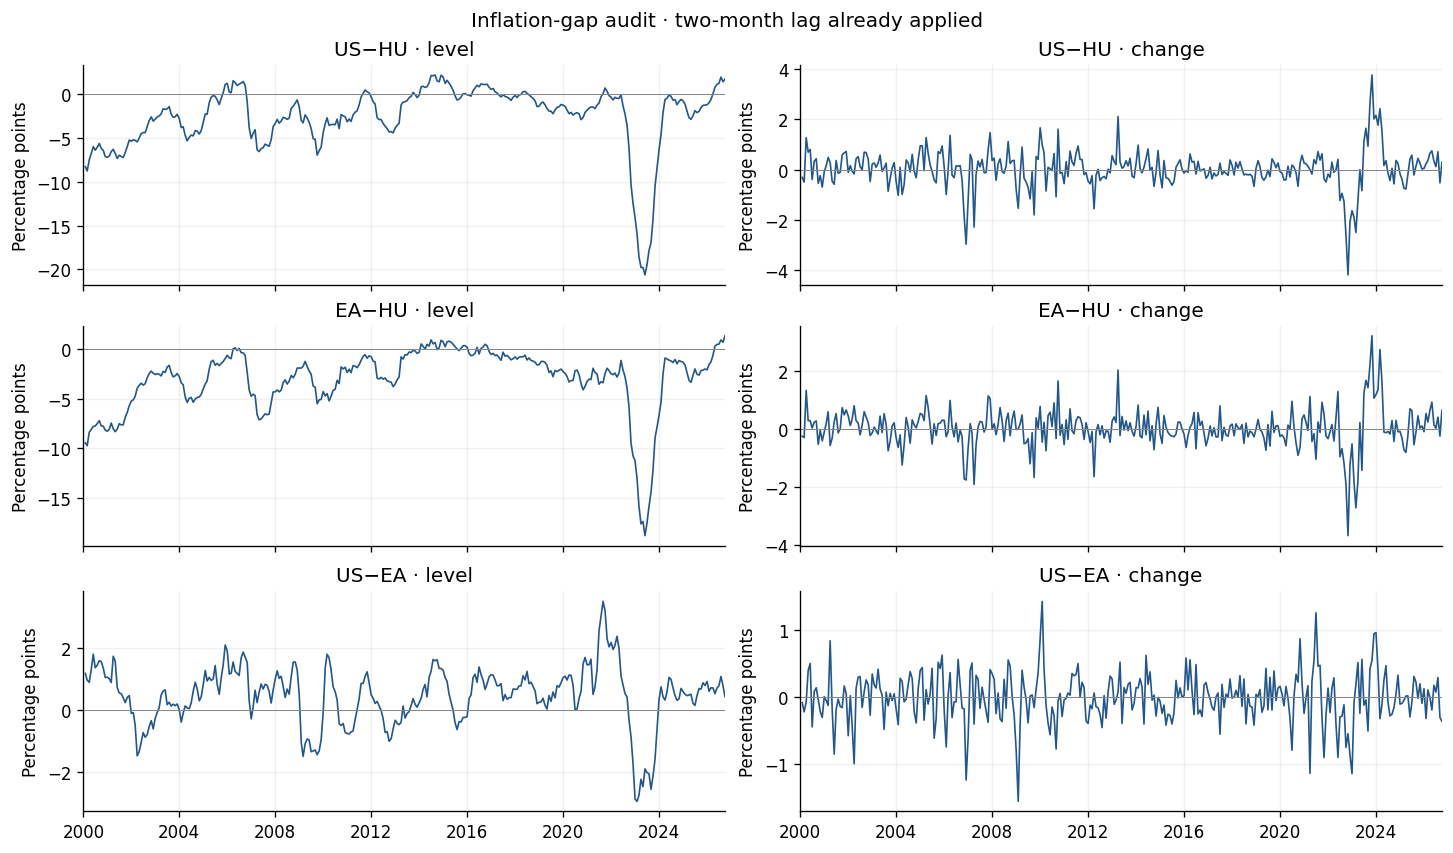

In [3]:
fig,axes=plt.subplots(3,2,figsize=(12,7),sharex=True,layout="constrained")
for row,name in enumerate(gap_levels.columns):
    for col,(form,frame) in enumerate([("level",gap_levels),("change",gap_changes)]):
        ax=axes[row,col]
        ax.plot(data.index.to_timestamp("M"),frame.loc[data.index,name],color="#235789",lw=1)
        ax.axhline(0,color="#888888",lw=.6)
        ax.set(title=f"{name.replace('_','−')} · {form}",ylabel="Percentage points",
               xlim=(data.index[0].start_time,data.index[-1].end_time))
fig.suptitle("Inflation-gap audit · two-month lag already applied")
plt.savefig(OUT/"01_inflation_conditioners.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 2. Make the currency prices functions of information

Following the linear currency-price specification in
[Antell and Vaihekoski, equation (18)](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf)
(numbering in the supplied April 2005 draft), estimate

$$\boxed{\lambda_{W,t}=\kappa_W'\widetilde Z_{W,t},\qquad
\lambda_{H,t}=\kappa_H'\widetilde Z_{H,t},\qquad
\lambda_{O,t}=\kappa_O'\widetilde Z_{O,t}.}$$

Each design includes an intercept and its selected, already lagged predictors. Demeaning/scaling over
the estimation sample is a linear reparameterisation; intercepts equal average fitted prices. A dummy's
slope is per one sample SD, not the entire pre/post difference. The normaliser table retains raw units.
Prices have unrestricted signs. This is an in-sample conditional-pricing study, not a real-time forecast.

For equity $i\in\{W,US,HU\}$,

$$\mu_{i,t}=\lambda_{W,t}H_{iW,t}+\lambda_{H,t}H_{iH,t}+\lambda_{O,t}H_{iO,t}
+\mathbf1_{i=US}\lambda_{US}H_{US,US,t}+\mathbf1_{i=HU}\lambda_{HU}H_{HU,HU,t}.$$

`constant_fx` reproduces notebook 06: world price varies, currency prices do not. `time_varying_fx`
adds **five HUF slopes and four other-FX slopes** with the default settings. Parameter counts are
**51 → 60** for scalar BEKK and **59 → 68** for diagonal BEKK. Local prices stay time-constant.

The same five return/factor series, FX appreciation signs, separate unrestricted FX VAR(6) means and
free-intercept stationary BEKK covariance process are retained. As in notebook 05, currency pricing
is tested through equity premia; the paper's additional spot-currency mean restriction is not imposed.
The two-factor currency basis, Hungary regime dummy and inflation transformations are documented
adaptations. USD and EUR systems are estimated separately; cross-numeraire equality is not imposed.

In [4]:
PRICE_SCALE = 0.01
N = 5
TRI = np.tril_indices(N)

def layout(x, pdesign, varying, covariance_model):
    k = 5 + pdesign["W"].shape[1]-1
    if varying: k += pdesign["H"].shape[1]-1 + pdesign["O"].shape[1]-1
    g = 2 * x.shape[1]
    dynamics = N * 2 if covariance_model == 'diagonal' else 2
    return k, g, dynamics

def unpack(theta, scales, x, pdesign, varying, covariance_model):
    k, g, dynamics = layout(x, pdesign, varying, covariance_model)
    q = len(theta)
    prices, dp = np.zeros(5), np.zeros((q, 5))
    prices[:] = PRICE_SCALE * theta[:5]
    dp[np.arange(5), np.arange(5)] = PRICE_SCALE
    gamma = theta[k:k+g].reshape(2, x.shape[1])
    C, dC = np.zeros((N, N)), np.zeros((q, N, N))
    for offset, (i, j) in enumerate(zip(*TRI)):
        index = k + g + offset
        value = np.exp(theta[index]) if i == j else theta[index]
        C[i, j] = scales[i] * value
        dC[index, i, j] = scales[i] * (value if i == j else 1.0)
    intercept = C @ C.T
    dintercept = dC @ C.T + C @ dC.transpose(0, 2, 1)
    weights = softmax(np.c_[np.zeros(dynamics // 2), theta[-dynamics:].reshape(-1, 2)], axis=1)
    alpha, beta = np.broadcast_to(weights[:, 1], N), np.broadcast_to(weights[:, 2], N)
    da, db = np.zeros((q, N)), np.zeros((q, N))
    for i in range(N):
        offset = i if covariance_model == 'diagonal' else 0
        u, v = q - dynamics + 2 * offset, q - dynamics + 2 * offset + 1
        da[u, i], da[v, i] = alpha[i] * (1-alpha[i]), -alpha[i]*beta[i]
        db[u, i], db[v, i] = -alpha[i]*beta[i], beta[i]*(1-beta[i])
    a, b = np.sqrt(alpha), np.sqrt(beta)
    da, db = da / (2*a), db / (2*b)
    aa, bb = np.outer(a, a), np.outer(b, b)
    daa = da[:, :, None]*a[None, None, :] + a[None, :, None]*da[:, None, :]
    dbb = db[:, :, None]*b[None, None, :] + b[None, :, None]*db[:, None, :]
    denominator = 1-aa-bb
    target = intercept / denominator
    dtarget = dintercept / denominator + intercept*(daa+dbb)/denominator**2
    return prices, dp, gamma, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta

def price_indices(pdesign, varying):
    world_end = 5 + pdesign["W"].shape[1]-1
    huf_end = world_end + (pdesign["H"].shape[1]-1 if varying else 0)
    other_end = huf_end + (pdesign["O"].shape[1]-1 if varying else 0)
    return {"W":np.r_[0,np.arange(5,world_end)],
            "H":np.r_[3,np.arange(world_end,huf_end)],
            "O":np.r_[4,np.arange(huf_end,other_end)]}

## 3. Joint likelihood and analytic derivatives

Use the same five-series Gaussian quasi-likelihood. Analytic derivatives propagate all three varying
prices and every nuisance coefficient through the full covariance recursion. Full BFGS exploration
and bounded L-BFGS-B polishing use deterministic/nested starts. Numerical convergence and residual
adequacy are checked separately. Repeated starts do not establish a global optimum.

In [5]:
def filter_model(theta, y, x, pdesign, scales, varying, covariance_model):
    prices, dp, gamma, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta = unpack(theta, scales, x, pdesign, varying, covariance_model)
    H, dH = target.copy(), dtarget.copy()
    n, q = len(y), len(theta)
    k, g, _ = layout(x, pdesign, varying, covariance_model)
    losses, scores = np.empty(n), np.empty((n, q))
    covariances, means, residuals = np.empty((n, N, N)), np.empty_like(y), np.empty_like(y)
    indices = price_indices(pdesign, varying)
    price_values, price_gradients = {}, {}
    for label in ["W","H","O"]:
        design = pdesign[label] if label=="W" or varying else np.ones((n,1))
        price_values[label] = PRICE_SCALE * (design @ theta[indices[label]])
        price_gradients[label] = np.zeros((n,q))
        price_gradients[label][:,indices[label]] = PRICE_SCALE * design
    for t in range(n):
        if not np.isfinite(H).all() or np.max(np.diag(H)) > 1e8:
            raise FloatingPointError('Unstable covariance recursion')
        chol, inverse = np.linalg.cholesky(H), np.linalg.inv(H)
        mu, dmu = np.zeros(N), np.zeros((q, N))
        for label, factor in [("W",0),("H",3),("O",4)]:
            value = price_values[label][t]
            derivative = price_gradients[label][t]
            mu[:3] += value * H[:3, factor]
            dmu[:, :3] += value * dH[:, :3, factor] + derivative[:, None] * H[None, :3, factor]
        for asset in (1, 2):
            mu[asset] += prices[asset] * H[asset, asset]
            dmu[:, asset] += prices[asset]*dH[:, asset, asset] + dp[:, asset]*H[asset, asset]
        mu[3:] = scales[3:] * (gamma @ x[t])
        for j in range(2):
            start = k + j*x.shape[1]
            dmu[start:start+x.shape[1], 3+j] = scales[3+j]*x[t]
        error, de = y[t]-mu, -dmu
        v = inverse @ error
        losses[t] = .5*(N*np.log(2*np.pi)+2*np.log(np.diag(chol)).sum()+error@v)
        scores[t] = .5*np.einsum('ij,kij->k', inverse-np.outer(v,v), dH) + de@v
        covariances[t], means[t], residuals[t] = H, mu, error
        shock = np.outer(error, error)
        dshock = de[:, :, None]*error[None, None, :] + error[None, :, None]*de[:, None, :]
        dH = dintercept + daa*shock + aa*dshock + dbb*H + bb*dH
        H = intercept + aa*shock + bb*H
    return {'losses':losses, 'scores':scores, 'H':covariances, 'mu':means, 'errors':residuals,
            'prices':prices, 'world_prices':price_values['W'], 'fx_prices':np.c_[price_values['H'],price_values['O']], 'price_coefficients':{a:PRICE_SCALE*theta[i] for a,i in indices.items()}, 'gamma':gamma, 'intercept':intercept, 'target':target, 'alpha':alpha, 'beta':beta}

def objective(theta, y, x, pdesign, scales, varying, covariance_model):
    try:
        with np.errstate(over='raise', invalid='raise', divide='raise'):
            f = filter_model(theta, y, x, pdesign, scales, varying, covariance_model)
        if not np.isfinite(f['losses']).all() or not np.isfinite(f['scores']).all():
            raise FloatingPointError('Non-finite likelihood or gradient')
        return f['losses'].mean(), f['scores'].mean(axis=0)
    except (FloatingPointError, np.linalg.LinAlgError):
        return 1e8 + theta@theta, 2*theta

In [6]:
def initial_theta(y, x, pdesign, scales, varying, covariance_model, alpha=.05, beta=.90):
    k, g, dynamics = layout(x, pdesign, varying, covariance_model)
    gamma = np.linalg.lstsq(x, y[:, 3:]/scales[3:], rcond=None)[0].T
    centred = y.copy()
    centred[:, 3:] -= (x @ gamma.T)*scales[3:]
    covariance = np.cov(centred, rowvar=False)
    remaining = 1-alpha-beta
    C = np.linalg.cholesky(remaining*covariance/np.outer(scales,scales))
    chol = [np.log(C[i,j]) if i==j else C[i,j] for i,j in zip(*TRI)]
    world = y[:,0].mean()/covariance[0,0]
    prices = [world] + [(y[:,i].mean()-world*covariance[i,0])/covariance[i,i] for i in (1,2)]
    prices += [0.,0.]
    return np.r_[np.asarray(prices)/PRICE_SCALE, np.zeros(k-5), gamma.ravel(), chol,
                 np.tile([np.log(alpha/remaining),np.log(beta/remaining)], dynamics//2)]

def constant_to_varying(theta, pdesign):
    position = 5+pdesign["W"].shape[1]-1
    count = pdesign["H"].shape[1]-1+pdesign["O"].shape[1]-1
    return np.r_[theta[:position],np.zeros(count),theta[position:]]

def scalar_to_diagonal(theta):
    return np.r_[theta[:-2], np.tile(theta[-2:], N)]

def parameter_bounds(x, pdesign, varying, covariance_model):
    k,g,dynamics = layout(x, pdesign, varying, covariance_model)
    cov_bounds = [(-8.,3.) if i==j else (-4.,4.) for i,j in zip(*TRI)]
    return [(-100.,100.)]*k + [(-3.,3.)]*g + cov_bounds + [(-10.,10.)]*dynamics

def fit_starts(y, x, pdesign, scales, varying, covariance_model, starts, maxiter=1600):
    bounds = np.asarray(parameter_bounds(x, pdesign, varying, covariance_model))
    args = (y, x, pdesign, scales, varying, covariance_model)
    runs, solutions = [], []
    for i, start in enumerate(starts, 1):
        # Full BFGS handles the weak price/covariance directions better than limited memory alone.
        coarse = minimize(objective, start, args=args, method='BFGS', jac=True,
                          options={'maxiter':maxiter, 'gtol':1e-6})
        # Restore numerical bounds after the exploratory BFGS step, then verify constrained convergence.
        projected = np.clip(coarse.x, bounds[:,0], bounds[:,1])
        result = minimize(objective, projected, args=args, method='L-BFGS-B', jac=True, bounds=bounds,
                          options={'maxiter':maxiter, 'ftol':1e-13, 'gtol':1e-7, 'maxls':50, 'maxcor':50})
        gradient = float(np.max(np.abs(result.jac)))
        print(f'  start {i}: success={result.success}, NLL={result.fun:.9f}, gradient={gradient:.2e}, '
              f'iterations={coarse.nit}+{result.nit}', flush=True)
        runs.append({'start':i, 'success':bool(result.success), 'mean_nll':float(result.fun),
                     'max_abs_gradient':gradient, 'iterations':int(coarse.nit+result.nit),
                     'BFGS_success':bool(coarse.success), 'polish_iterations':int(result.nit),
                     'message':str(result.message)})
        solutions.append(result)
    valid = [r for r in solutions if r.success and np.isfinite(r.fun) and r.fun<1e7
             and np.max(np.abs(r.jac))<1e-4]
    if not valid:
        raise RuntimeError('No converged fit with a small gradient; inspect starts and MAX_ITER.')
    best = min(valid, key=lambda r:r.fun)
    lower = [r for r in solutions if np.isfinite(r.fun) and r.fun<best.fun-1e-7]
    if lower:
        raise RuntimeError('A lower nonconverged candidate exists. Increase MAX_ITER before inference.')
    return best, runs

def numerical_gradient(function, theta, step=1e-5):
    result=np.empty_like(theta)
    for j in range(len(theta)):
        delta=step*(1+abs(theta[j])); plus=theta.copy();minus=theta.copy()
        plus[j]+=delta;minus[j]-=delta
        result[j]=(function(plus)-function(minus))/(2*delta)
    return result

def loss_hessian(theta, y, x, pdesign, scales, varying, covariance_model, step=1e-4):
    result=np.empty((len(theta),len(theta)))
    for j in range(len(theta)):
        delta=step*(1+abs(theta[j]));plus=theta.copy();minus=theta.copy()
        plus[j]+=delta;minus[j]-=delta
        result[:,j]=(objective(plus,y,x,pdesign,scales,varying,covariance_model)[1]-objective(minus,y,x,pdesign,scales,varying,covariance_model)[1])/(2*delta)
    return (result+result.T)/2

def var_radius(gamma):
    lags=(gamma.shape[1]-1)//2
    if not lags: return 0.
    top=np.concatenate([gamma[:,1+2*j:3+2*j] for j in range(lags)],axis=1)
    companion=np.r_[top,np.c_[np.eye(2*(lags-1)),np.zeros((2*(lags-1),2))]]
    return float(np.max(np.abs(np.linalg.eigvals(companion))))

## 4. Verify notebook 06 and exact nesting

Verify source hashes, sample, world instrument design and saved constant-FX fitted paths. Setting all
new FX slopes to zero must reproduce each loss exactly. Check analytic gradients with nonzero
world/HUF/other-currency slopes and unequal diagonal dynamics before fitting.

In [7]:
baseline_hashes={}
def baseline_bytes(name):
    content=(BASELINE/name).read_bytes()
    baseline_hashes[name]=hashlib.sha256(content).hexdigest()
    return content
prior=json.loads(baseline_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["raw_ecb_sha256"]!=fx_source_sha256
        or prior["raw_fred_sha256"]!=fred_sha256 or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1])
        or prior["FX_VAR_lags"]!=FX_VAR_LAGS or prior["world_instruments"]!=WORLD_INSTRUMENTS):
    raise ValueError("Run notebook 06 with the same frozen sample, global instruments and FX lags first.")
old_world=pd.read_csv(BytesIO(baseline_bytes("conditioning_design.csv")),index_col=0,float_precision="round_trip")
fits,checks={},[]
for currency,y in samples.items():
    x,scales,pdesign=designs[currency],scales_by_currency[currency],price_designs[currency]
    np.testing.assert_allclose(pdesign["W"],old_world.to_numpy(),atol=1e-12,rtol=0)
    for covariance_model in COVARIANCE_MODELS:
        old_key=f"{currency}_{covariance_model}_time_varying"
        record=json.loads(baseline_bytes(f"fit_{old_key}.json"))
        for field,value in {"source_sha256":manifest["exports"]["dataset.csv"],"perspective":currency,
                "covariance_model":covariance_model,"first":str(data.index[0]),"last":str(data.index[-1]),
                "world_instruments":WORLD_INSTRUMENTS,"FX_VAR_lags":FX_VAR_LAGS}.items():
            if record["config"].get(field)!=value: raise ValueError("Mismatched notebook 06 benchmark.")
        with np.load(BytesIO(baseline_bytes(f"parameters_{old_key}.npz")),allow_pickle=False) as arrays:
            saved={k:arrays[k].copy() for k in arrays.files}
        theta=np.asarray(record["theta"],dtype=float)
        np.testing.assert_allclose(theta,saved["theta"],atol=0,rtol=0)
        f=filter_model(theta,y,x,pdesign,scales,False,covariance_model)
        np.testing.assert_allclose(f["losses"].mean(),record["mean_nll"],atol=1e-10,rtol=0)
        for name,old_name in [("H","H"),("mu","mu"),("errors","residuals")]:
            np.testing.assert_allclose(f[name],saved[old_name],atol=1e-8,rtol=1e-10)
        if np.max(np.abs(f["scores"].mean(axis=0)))>=1e-4: raise ValueError("Baseline gradient fails.")
        key=f"{currency}_{covariance_model}_constant_fx"
        fits[key]={"theta":theta,"filter":f,"currency":currency,"covariance_model":covariance_model,
                   "model":"constant_fx","varying":False,"y":y,"x":x,"scales":scales,"pdesign":pdesign}
        same=filter_model(constant_to_varying(theta,pdesign),y,x,pdesign,scales,True,covariance_model)
        np.testing.assert_allclose(f["losses"],same["losses"],atol=1e-12,rtol=0)
        candidate=initial_theta(y,x,pdesign,scales,True,covariance_model)
        for label,indices in price_indices(pdesign,True).items(): candidate[indices]=np.linspace(.2,-.15,len(indices))
        if covariance_model=="diagonal": candidate[-10:]+=np.linspace(-.1,.1,10)
        small={k:v[:40] for k,v in pdesign.items()}
        analytic=objective(candidate,y[:40],x[:40],small,scales,True,covariance_model)[1]
        numeric=numerical_gradient(lambda th:objective(th,y[:40],x[:40],small,scales,True,covariance_model)[0],candidate)
        np.testing.assert_allclose(analytic,numeric,atol=4e-6,rtol=4e-5)
        checks.append({"perspective":currency,"covariance_model":covariance_model,
                       "baseline_mean_nll":f["losses"].mean(),"max_gradient_error":np.max(np.abs(analytic-numeric))})
display(pd.DataFrame(checks))

,perspective,covariance_model,baseline_mean_nll,max_gradient_error
0,USD,scalar,11.594635,3.572485e-08
1,USD,diagonal,11.576393,2.736305e-08
2,EUR,scalar,11.600629,4.454824e-08
3,EUR,diagonal,11.570945,3.053908e-08


## 5. Estimate both varying currency-price functions

The alternative starts at the fitted constant-FX restriction, at two moment-based parameter vectors,
and, for diagonal covariance, at the fitted scalar alternative. Cache acceptance requires matching
model code, actual returns/mean/price designs, instrument choices, baseline source, settings and
runtime versions, plus likelihood/gradient/bound checks. A stale cache is only an optional start.

In [8]:
notebook=json.loads((ROOT/"07_time_varying_currency.ipynb").read_text())
model_sources=["".join(c["source"]) for c in notebook["cells"] if c["cell_type"]=="code"
               and any(token in "".join(c["source"]) for token in ["def layout(","def filter_model(","def initial_theta("])]
model_code_sha256=hashlib.sha256("\n".join(model_sources).encode()).hexdigest()
start_records=[]
for currency,y in samples.items():
    x,scales,pdesign=designs[currency],scales_by_currency[currency],price_designs[currency]
    for covariance_model in COVARIANCE_MODELS:
        key=f"{currency}_{covariance_model}_time_varying_fx"
        constant_key=f"{currency}_{covariance_model}_constant_fx"
        print(key,flush=True)
        config={"model_version":MODEL_VERSION,"model_code_sha256":model_code_sha256,"spec":spec,
            "source_sha256":manifest["exports"]["dataset.csv"],"fx_sha256":fx_source_sha256,"fred_sha256":fred_sha256,"hicp_sha256":hicp_sha256,
            "perspective":currency,"covariance_model":covariance_model,"first":str(data.index[0]),"last":str(data.index[-1]),
            "FX_VAR_lags":FX_VAR_LAGS,"starts":START_DYNAMICS,"max_iter":MAX_ITER,
            "baseline_sha256":baseline_hashes[f"fit_{currency}_{covariance_model}_time_varying.json"],
            "packages":versions,"python":platform.python_version()}
        payload=json.dumps(config,sort_keys=True).encode()+y.tobytes()+x.tobytes()+b"".join(pdesign[a].tobytes() for a in ["W","H","O"])
        fingerprint=hashlib.sha256(payload).hexdigest()
        path=OUT/f"fit_{key}.json"
        cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        record=None
        bounds=np.asarray(parameter_bounds(x,pdesign,True,covariance_model))
        candidate=np.asarray(cached["theta"],dtype=float) if cached else np.array([])
        usable=candidate.shape==(len(bounds),) and np.isfinite(candidate).all()
        if usable and cached.get("fingerprint")==fingerprint and (candidate>=bounds[:,0]).all() and (candidate<=bounds[:,1]).all():
            value,gradient=objective(candidate,y,x,pdesign,scales,True,covariance_model)
            if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:
                record=cached
                print("  verified cached fit",flush=True)
        starts=[constant_to_varying(fits[constant_key]["theta"],pdesign)]
        starts += [initial_theta(y,x,pdesign,scales,True,covariance_model,a,b) for a,b in START_DYNAMICS]
        nested_keys=[constant_key]
        scalar_key=f"{currency}_scalar_time_varying_fx"
        if covariance_model=="diagonal" and scalar_key in fits:
            starts.insert(0,scalar_to_diagonal(fits[scalar_key]["theta"]))
            nested_keys.append(scalar_key)
        if usable: starts.insert(0,np.clip(candidate,bounds[:,0],bounds[:,1]))
        if record is None:
            best,runs=fit_starts(y,x,pdesign,scales,True,covariance_model,starts,MAX_ITER)
            record={"fingerprint":fingerprint,"config":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
            path.write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
        theta=np.asarray(record["theta"],dtype=float)
        f=filter_model(theta,y,x,pdesign,scales,True,covariance_model)
        for nested_key in nested_keys:
            if f["losses"].sum()>fits[nested_key]["filter"]["losses"].sum()+1e-5: raise ValueError(f"Worse than nested {nested_key}.")
        fits[key]={"theta":theta,"filter":f,"currency":currency,"covariance_model":covariance_model,
                   "model":"time_varying_fx","varying":True,"y":y,"x":x,"scales":scales,"pdesign":pdesign}
        start_records += [{"perspective":currency,"covariance_model":covariance_model,**r} for r in record["starts"]]
starts_table=pd.DataFrame(start_records)
display(starts_table.drop(columns="message").round(8))

USD_scalar_time_varying_fx


  verified cached fit


USD_diagonal_time_varying_fx


  verified cached fit


EUR_scalar_time_varying_fx


  verified cached fit


EUR_diagonal_time_varying_fx


  verified cached fit


,perspective,covariance_model,BFGS_success,iterations,max_abs_gradient,mean_nll,polish_iterations,start,success
0,USD,scalar,True,235,3.400000e-07,11.579953,1,1,True
1,USD,scalar,True,277,3.900000e-07,11.579953,1,2,True
2,USD,scalar,True,275,1.300000e-07,11.579953,1,3,True
3,USD,diagonal,True,325,3.300000e-07,11.555370,1,1,True
4,USD,diagonal,True,303,5.400000e-07,11.555370,1,2,True
5,USD,diagonal,True,331,1.830000e-06,11.555370,1,3,True
6,USD,diagonal,True,354,1.940000e-06,11.555369,2,4,True
7,EUR,scalar,True,256,2.000000e-08,11.585202,1,1,True
8,EUR,scalar,True,273,7.200000e-07,11.585202,1,2,True
9,EUR,scalar,True,271,1.740000e-06,11.585202,1,3,True


## 6. Joint uncertainty, constancy and zero-price tests

Use the full QML sandwich $A^{-1}BA^{-1}/T$, including world/FX/local price, VAR and covariance
parameters. Retain the numerical gates from notebook 06: bounds, positive/stable curvature, stable
VAR and price standard errors at two Hessian steps. Withhold inference when these fail.
The score meat assumes correct conditional moments; residual diagnostics still limit interpretation.

The main null is **both FX prices constant**: all added FX slopes zero (9 df by default).
Factor-specific constancy tests use 5 and 4 df. **Both FX prices zero** tests all currency coefficients,
including intercepts (11 df). A zero intercept alone answers neither question. Local-information
restrictions test the inflation/regime slopes with global predictors retained. Results are conditional
asymptotic Wald tests; no ordinary Gaussian LR chi-square or multiple-testing adjustment is used.

The joint test uses the full cross-factor coefficient covariance. Its result need not match the
two factor-specific tests viewed separately.

In [9]:
fit_rows,coefficient_rows,wald_rows,path_rows=[],[],[],[]
for key,fit in fits.items():
    theta,f,y,x,pdesign,scales=fit["theta"],fit["filter"],fit["y"],fit["x"],fit["pdesign"],fit["scales"]
    varying,covariance_model=fit["varying"],fit["covariance_model"]
    args=(y,x,pdesign,scales,varying,covariance_model)
    hessian,small=loss_hessian(theta,*args),loss_hessian(theta,*args,step=5e-5)
    condition=np.linalg.cond(hessian)
    sensitivity=np.max(np.abs(hessian-small))/max(1.,np.max(np.abs(small)))
    bounds=np.asarray(parameter_bounds(x,pdesign,varying,covariance_model))
    boundary=bool(np.min(np.minimum(theta-bounds[:,0],bounds[:,1]-theta))<1e-4)
    radius=var_radius(f["gamma"])
    ready=bool(np.linalg.eigvalsh(hessian).min()>0 and condition<1e9 and sensitivity<1e-3 and not boundary and radius<1)
    covariance=np.full_like(hessian,np.nan);se_difference=np.nan
    if ready:
        scores=f["scores"]-f["scores"].mean(axis=0);meat=scores.T@scores/len(y)
        def sandwich(A):
            bread=np.linalg.inv(A);V=bread@meat@bread.T/len(y)
            return (V+V.T)/2
        covariance,alternative=sandwich(hessian),sandwich(small)
        k=layout(x,pdesign,varying,covariance_model)[0]
        finite=(np.isfinite(covariance).all() and (np.diag(covariance)>0).all()
                and np.linalg.eigvalsh(small).min()>0 and (np.diag(alternative)>0).all())
        if finite:se_difference=np.max(np.abs(np.sqrt(np.diag(alternative)[:k])/np.sqrt(np.diag(covariance)[:k])-1))
        ready=bool(finite and se_difference<SE_STEP_TOL)
    fit["covariance"]=covariance if ready else np.full_like(hessian,np.nan)
    fit["inference_ready"]=ready
    currency,model=fit["currency"],fit["model"]
    indices=price_indices(pdesign,varying)
    risk_labels={"W":"World","H":"HUF FX","O":f"{FX_NAMES[currency][1]} FX"}
    fit["price_se"]={}
    for label,idx in indices.items():
        active=label=="W" or varying
        terms=["intercept"]+(list(feature_frames[currency][label].columns) if active else [])
        for j,term in zip(idx,terms):
            value=PRICE_SCALE*theta[j];se=PRICE_SCALE*np.sqrt(covariance[j,j]) if ready else np.nan
            coefficient_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,
                "risk":risk_labels[label],"term":term,"estimate":value,"robust_se":se,
                "p_value":2*norm.sf(abs(value/se)) if ready else np.nan,"ci95_low":value-1.96*se,"ci95_high":value+1.96*se})
        design=pdesign[label] if active else np.ones((len(y),1))
        se_path=PRICE_SCALE*np.sqrt(np.maximum(np.einsum("ti,ij,tj->t",design,covariance[np.ix_(idx,idx)],design),0)) if ready else np.full(len(y),np.nan)
        fit["price_se"][label]=se_path
        values=f["world_prices"] if label=="W" else f["fx_prices"][:,0 if label=="H" else 1]
        for t,month in enumerate(data.index):
            path_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"risk":risk_labels[label],
                "month":str(month),"price":values[t],"robust_se":se_path[t],"ci95_low":values[t]-1.96*se_path[t],"ci95_high":values[t]+1.96*se_path[t]})
    for j,risk in [(1,"US local"),(2,"Hungary local")]:
        value=PRICE_SCALE*theta[j];se=PRICE_SCALE*np.sqrt(covariance[j,j]) if ready else np.nan
        coefficient_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"risk":risk,"term":"intercept",
            "estimate":value,"robust_se":se,"p_value":2*norm.sf(abs(value/se)) if ready else np.nan,"ci95_low":value-1.96*se,"ci95_high":value+1.96*se})
    restrictions=[("FX prices zero",np.r_[indices["H"],indices["O"]]),("HUF price zero",indices["H"]),
                  ("Other FX price zero",indices["O"]),("World price constant",indices["W"][1:]),("Local prices zero",np.array([1,2]))]
    if varying:
        local_idx=np.r_[indices["H"][1+len(WORLD_INSTRUMENTS):],indices["O"][1+len(WORLD_INSTRUMENTS):]]
        restrictions=[("FX prices constant",np.r_[indices["H"][1:],indices["O"][1:]]),
                      ("HUF price constant",indices["H"][1:]),("Other FX price constant",indices["O"][1:]),
                      ("Local FX information zero",local_idx)]+restrictions
    for name,idx in restrictions:
        variance=covariance[np.ix_(idx,idx)]
        valid=ready and np.linalg.eigvalsh(variance).min()>0 and np.linalg.cond(variance)<1e9
        statistic=theta[idx]@np.linalg.solve(variance,theta[idx]) if valid else np.nan
        wald_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"test":name,
            "Wald_statistic":statistic,"df":len(idx),"robust_p_value":chi2.sf(statistic,len(idx)) if valid else np.nan})
    ll=-f["losses"].sum()
    fit_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"n":len(y),"parameters":len(theta),
        "loglik":ll,"AIC":-2*ll+2*len(theta),"BIC":-2*ll+np.log(len(y))*len(theta),
        "max_abs_gradient":np.max(np.abs(f["scores"].mean(axis=0))),"min_H_eigenvalue":np.linalg.eigvalsh(f["H"]).min(),
        "Hessian_condition":condition,"curvature_step_difference":sensitivity,"price_SE_step_difference":se_difference,
        "near_bound":boundary,"FX_VAR_radius":radius,"numerical_inference_ready":ready})
fit_table=pd.DataFrame(fit_rows).set_index(["perspective","covariance_model","model"]).sort_index()
coefficient_table=pd.DataFrame(coefficient_rows).set_index(["perspective","covariance_model","model","risk","term"]).sort_index()
wald_table=pd.DataFrame(wald_rows).set_index(["perspective","covariance_model","model","test"]).sort_index()
price_paths=pd.DataFrame(path_rows).set_index(["perspective","covariance_model","model","risk","month"]).sort_index()
display(fit_table.round(6))
tv_coefficients=coefficient_table.xs("time_varying_fx",level="model")
display(tv_coefficients.loc[tv_coefficients.index.get_level_values("risk").str.contains("FX")].round(5))
tv_tests=wald_table.xs("time_varying_fx",level="model")
display(tv_tests.loc[tv_tests.index.get_level_values("test").isin(["FX prices constant","HUF price constant","Other FX price constant","FX prices zero"])].round(4))

n  parameters       loglik  \
perspective covariance_model model                                           
EUR         diagonal         constant_fx      321          59 -3714.273270   
                             time_varying_fx  321          68 -3709.026945   
            scalar           constant_fx      321          51 -3723.801755   
                             time_varying_fx  321          60 -3718.849916   
USD         diagonal         constant_fx      321          59 -3716.022148   
                             time_varying_fx  321          68 -3709.273575   
            scalar           constant_fx      321          51 -3721.877799   
                             time_varying_fx  321          60 -3717.164939   

                                                      AIC          BIC  \
perspective covariance_model model                                       
EUR         diagonal         constant_fx      7546.546540  7769.061566   
                             time_varying_fx  7554.053891  7810.511887   
            scalar           constant_fx      7549.603510  7741.947007   
                             time_varying_fx  7557.699832  7783.986299   
USD         diagonal         constant_fx      7550.044297  7772.559323   
                             time_varying_fx  7554.547151  7811.005147   
            scalar           constant_fx      7545.755598  7738.099096   
                             time_varying_fx  7554.329877  7780.616345   

                                              max_abs_gradient  \
perspective covariance_model model                               
EUR         diagonal         constant_fx              0.000042   
                             time_varying_fx          0.000043   
            scalar           constant_fx              0.000001   
                             time_varying_fx          0.000000   
USD         diagonal         constant_fx              0.000000   
                             time_varying_fx          0.000002   
            scalar           constant_fx              0.000000   
                             time_varying_fx          0.000000   

                                              min_H_eigenvalue  \
perspective covariance_model model                               
EUR         diagonal         constant_fx              0.339403   
                             time_varying_fx          0.339242   
            scalar           constant_fx              0.374798   
                             time_varying_fx          0.373031   
USD         diagonal         constant_fx              0.342727   
                             time_varying_fx          0.345450   
            scalar           constant_fx              0.358593   
                             time_varying_fx          0.360105   

                                              Hessian_condition  \
perspective covariance_model model                                
EUR         diagonal         constant_fx           4.882861e+12   
                             time_varying_fx       7.480284e+12   
            scalar           constant_fx           1.280032e+07   
                             time_varying_fx       1.495893e+07   
USD         diagonal         constant_fx           1.904792e+07   
                             time_varying_fx       1.927384e+09   
            scalar           constant_fx           2.163474e+07   
                             time_varying_fx       3.233751e+07   

                                              curvature_step_difference  \
perspective covariance_model model                                        
EUR         diagonal         constant_fx                       0.000001   
                             time_varying_fx                   0.000001   
            scalar           constant_fx                       0.000001   
                             time_varying_fx                   0.000001   
USD         diagonal         constant_fx                       0.000000   
        

estimate  \
perspective covariance_model risk   term                                          
EUR         diagonal         HUF FX HUF_inflation_gap_change_lag2_pp   -0.00118   
                                    credit_spread_lag1_pp               0.03707   
                                    floating_regime_known              -0.04691   
                                    intercept                           0.60018   
                                    short_rate_change_lag1_pp           0.11136   
                                    term_spread_change_lag1_pp          0.07334   
                             USD FX credit_spread_lag1_pp              -0.01853   
                                    intercept                          -0.16221   
                                    other_inflation_gap_level_lag2_pp   0.00575   
                                    short_rate_change_lag1_pp           0.03746   
                                    term_spread_change_lag1_pp          0.07032   
            scalar           HUF FX HUF_inflation_gap_change_lag2_pp    0.00020   
                                    credit_spread_lag1_pp              -0.00269   
                                    floating_regime_known              -0.04053   
                                    intercept                           0.00422   
                                    short_rate_change_lag1_pp           0.06285   
                                    term_spread_change_lag1_pp          0.03598   
                             USD FX credit_spread_lag1_pp              -0.03389   
                                    intercept                          -0.08707   
                                    other_inflation_gap_level_lag2_pp   0.01794   
                                    short_rate_change_lag1_pp           0.00743   
                                    term_spread_change_lag1_pp          0.07162   
USD         diagonal         EUR FX credit_spread_lag1_pp               0.24193   
                                    intercept                           0.12914   
                                    other_inflation_gap_level_lag2_pp   0.03165   
                                    short_rate_change_lag1_pp           0.05346   
                                    term_spread_change_lag1_pp          0.03202   
                             HUF FX HUF_inflation_gap_change_lag2_pp   -0.00448   
                                    credit_spread_lag1_pp              -0.09015   
                                    floating_regime_known              -0.01287   
                                    intercept                           0.00279   
                                    short_rate_change_lag1_pp           0.00115   
                                    term_spread_change_lag1_pp         -0.03089   
            scalar           EUR FX credit_spread_lag1_pp               0.05010   
                                    intercept                          -0.05183   
                                    other_inflation_gap_level_lag2_pp   0.01586   
                                    short_rate_change_lag1_pp          -0.02138   
                                    term_spread_change_lag1_pp         -0.05761   
                             HUF FX HUF_inflation_gap_change_lag2_pp   -0.00098   
                                    credit_spread_lag1_pp               0.00733   
                                    floating_regime_known              -0.01866   
                                    intercept                           0.11159   
                                    short_rate_change_lag1_pp           0.04829   
                                    term_spread_change_lag1_pp          0.01656   

                                                                       robust_se  \
perspective covariance_model risk   term                                           
EUR         diagonal         HUF FX HUF_inflation_gap_change_lag2_pp         NaN   


Wald_statistic  df  \
perspective covariance_model test                                          
EUR         diagonal         FX prices constant                  NaN   9   
                             FX prices zero                      NaN  11   
                             HUF price constant                  NaN   5   
                             Other FX price constant             NaN   4   
            scalar           FX prices constant              14.9708   9   
                             FX prices zero                  16.9382  11   
                             HUF price constant               2.4074   5   
                             Other FX price constant          3.3819   4   
USD         diagonal         FX prices constant                  NaN   9   
                             FX prices zero                      NaN  11   
                             HUF price constant                  NaN   5   
                             Other FX price constant             NaN   4   
            scalar           FX prices constant              10.2505   9   
                             FX prices zero                  11.0100  11   
                             HUF price constant               3.2275   5   
                             Other FX price constant          1.5538   4   

                                                      robust_p_value  
perspective covariance_model test                                     
EUR         diagonal         FX prices constant                  NaN  
                             FX prices zero                      NaN  
                             HUF price constant                  NaN  
                             Other FX price constant             NaN  
            scalar           FX prices constant               0.0917  
                             FX prices zero                   0.1097  
                             HUF price constant               0.7904  
                             Other FX price constant          0.4961  
USD         diagonal         FX prices constant                  NaN  
                             FX prices zero                      NaN  
                             HUF price constant                  NaN  
                             Other FX price constant             NaN  
            scalar           FX prices constant               0.3306  
                             FX prices zero                   0.4424  
                             HUF price constant               0.6650  
                             Other FX price constant          0.8171

## 7. Residual adequacy

Keep the same marginal and whitened cross-product screens for all five innovations. They are
nominal exploratory diagnostics, without full fitted-GARCH degrees-of-freedom or multiple-test
adjustment. A numerically valid sandwich does not repair remaining mean/variance misspecification.
The two currency bases and conditioning sets are interpreted within their own investor perspective.

In [10]:
residual_rows,cross_rows=[],[]
for key,fit in fits.items():
    f=fit["filter"]
    z=f["errors"]/np.sqrt(np.diagonal(f["H"],axis1=1,axis2=2))
    white=np.linalg.solve(np.linalg.cholesky(f["H"]),f["errors"][...,None])[...,0]
    labels=ASSETS[:3]+[f"{c} FX" for c in FX_NAMES[fit["currency"]]]
    prefix={"perspective":fit["currency"],"covariance_model":fit["covariance_model"],"model":fit["model"]}
    for j,label in enumerate(labels):
        residual_rows.append({**prefix,"series":label,"z_mean":z[:,j].mean(),"z_sd":z[:,j].std(ddof=1),
            "LB_z_p":acorr_ljungbox(z[:,j],lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0],
            "LB_z_squared_p":acorr_ljungbox((z[:,j]-z[:,j].mean())**2,lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0],
            "ARCH_LM_p":het_arch(z[:,j],nlags=TEST_LAGS,ddof=0,result_object=False)[1]})
    for i in range(5):
        for j in range(i+1,5):
            product=white[:,i]*white[:,j]
            cross_rows.append({**prefix,"pair":f"{labels[i]} / {labels[j]}","mean_whitened_product":product.mean(),
                "LB_product_p":acorr_ljungbox(product,lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0]})
residual_table=pd.DataFrame(residual_rows).set_index(["perspective","covariance_model","model","series"]).sort_index()
cross_table=pd.DataFrame(cross_rows).set_index(["perspective","covariance_model","model","pair"]).sort_index()
display(residual_table.xs("time_varying_fx",level="model").round(4))
display(cross_table.xs("time_varying_fx",level="model").query("LB_product_p < 0.05").round(4))

z_mean    z_sd  LB_z_p  LB_z_squared_p  \
perspective covariance_model series                                            
EUR         diagonal         HUF FX  -0.0207  0.9981  0.0379          0.0002   
                             Hungary -0.0405  0.9980  0.6417          0.0624   
                             US      -0.0472  1.0085  0.2143          0.1081   
                             USD FX   0.0098  0.9761  0.6771          0.1417   
                             World   -0.0505  1.0088  0.6662          0.1023   
            scalar           HUF FX   0.0070  0.9922  0.1093          0.1230   
                             Hungary -0.0146  1.0053  0.6777          0.4602   
                             US      -0.0410  1.0081  0.1070          0.1760   
                             USD FX   0.0009  0.9937  0.6336          0.0211   
                             World   -0.0421  1.0205  0.2852          0.0644   
USD         diagonal         EUR FX  -0.0259  0.9940  0.6203          0.0054   
                             HUF FX  -0.0289  0.9873  0.6545          0.2426   
                             Hungary -0.0623  1.0116  0.6038          0.4987   
                             US      -0.0936  1.0078  0.4704          0.1599   
                             World   -0.0910  1.0211  0.6911          0.0399   
            scalar           EUR FX  -0.0022  0.9980  0.6112          0.0175   
                             HUF FX   0.0028  1.0049  0.7776          0.0381   
                             Hungary -0.0182  1.0110  0.6477          0.6616   
                             US      -0.0669  1.0162  0.4562          0.0123   
                             World   -0.0649  1.0322  0.6854          0.0045   

                                      ARCH_LM_p  
perspective covariance_model series              
EUR         diagonal         HUF FX      0.0007  
                             Hungary     0.0710  
                             US          0.2362  
                             USD FX      0.1368  
                             World       0.1778  
            scalar           HUF FX      0.1337  
                             Hungary     0.3074  
                             US          0.2970  
                             USD FX      0.0215  
                             World       0.1186  
USD         diagonal         EUR FX      0.0080  
                             HUF FX      0.2221  
                             Hungary     0.3761  
                             US          0.0461  
                             World       0.0227  
            scalar           EUR FX      0.0220  
                             HUF FX      0.0326  
                             Hungary     0.5917  
                             US          0.0101  
                             World       0.0055

mean_whitened_product  \
perspective covariance_model pair                                    
EUR         diagonal         World / US                     0.0093   
            scalar           World / US                    -0.0413   
USD         diagonal         World / US                    -0.0133   
            scalar           World / HUF FX                 0.0174   
                             World / US                    -0.0302   

                                             LB_product_p  
perspective covariance_model pair                          
EUR         diagonal         World / US            0.0199  
            scalar           World / US            0.0343  
USD         diagonal         World / US            0.0082  
            scalar           World / HUF FX        0.0046  
                             World / US            0.0026

## 8. Currency-price paths and Hungarian premium decomposition

Plot each FX price with its pointwise robust 95% interval when inference passes the numerical gates.
Dashed lines are the corresponding constant-FX model point estimates; bands are not simultaneous
or return prediction intervals. Price paths are estimated in sample and can be negative.

The decomposition replaces both constant FX terms with their time-varying counterparts. Verify the
world, HUF FX, other FX and local components sum to the fitted Hungarian equity mean each month.
Components are point estimates and can offset strongly; withheld-inference fits are illustrative.

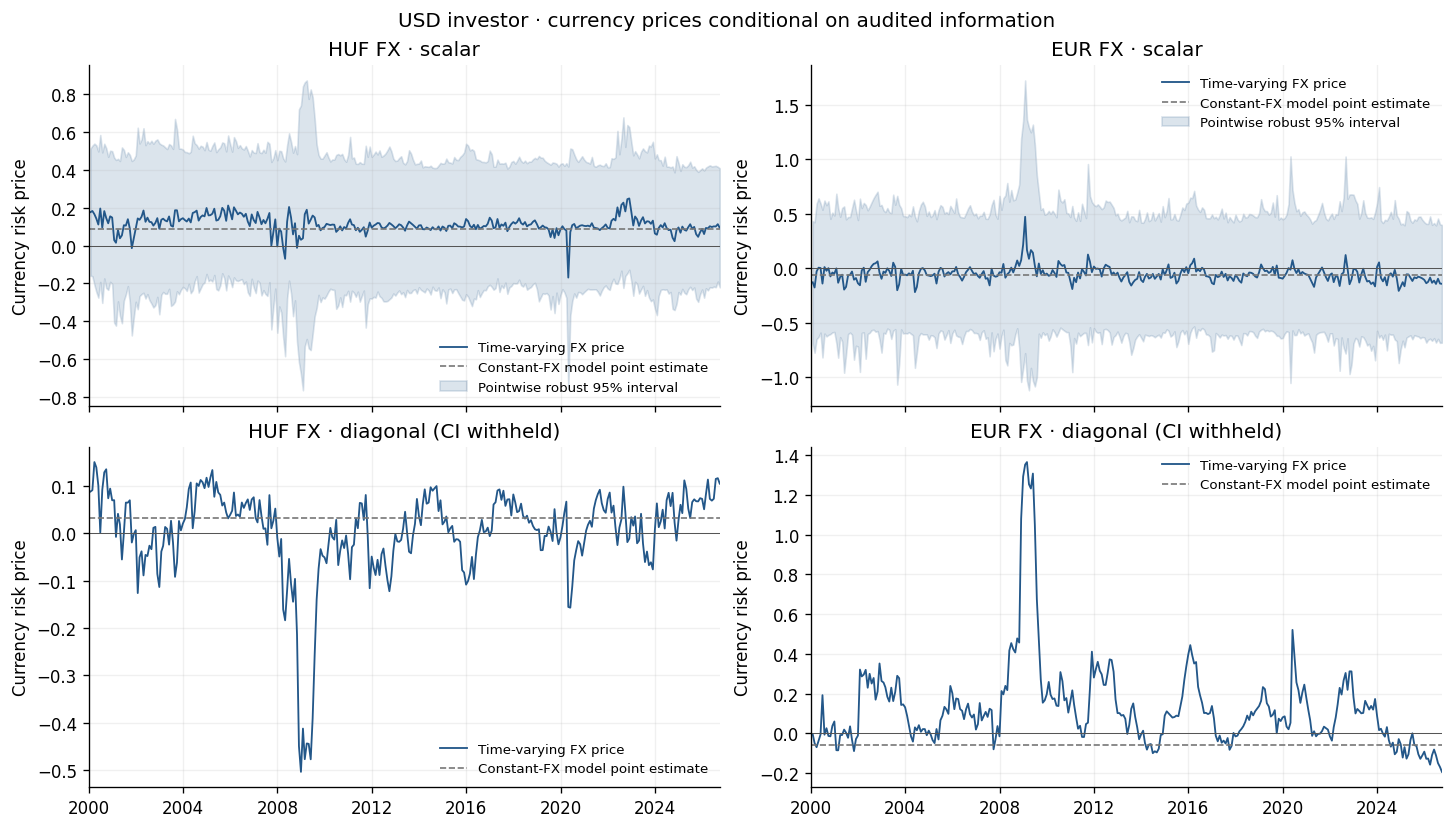

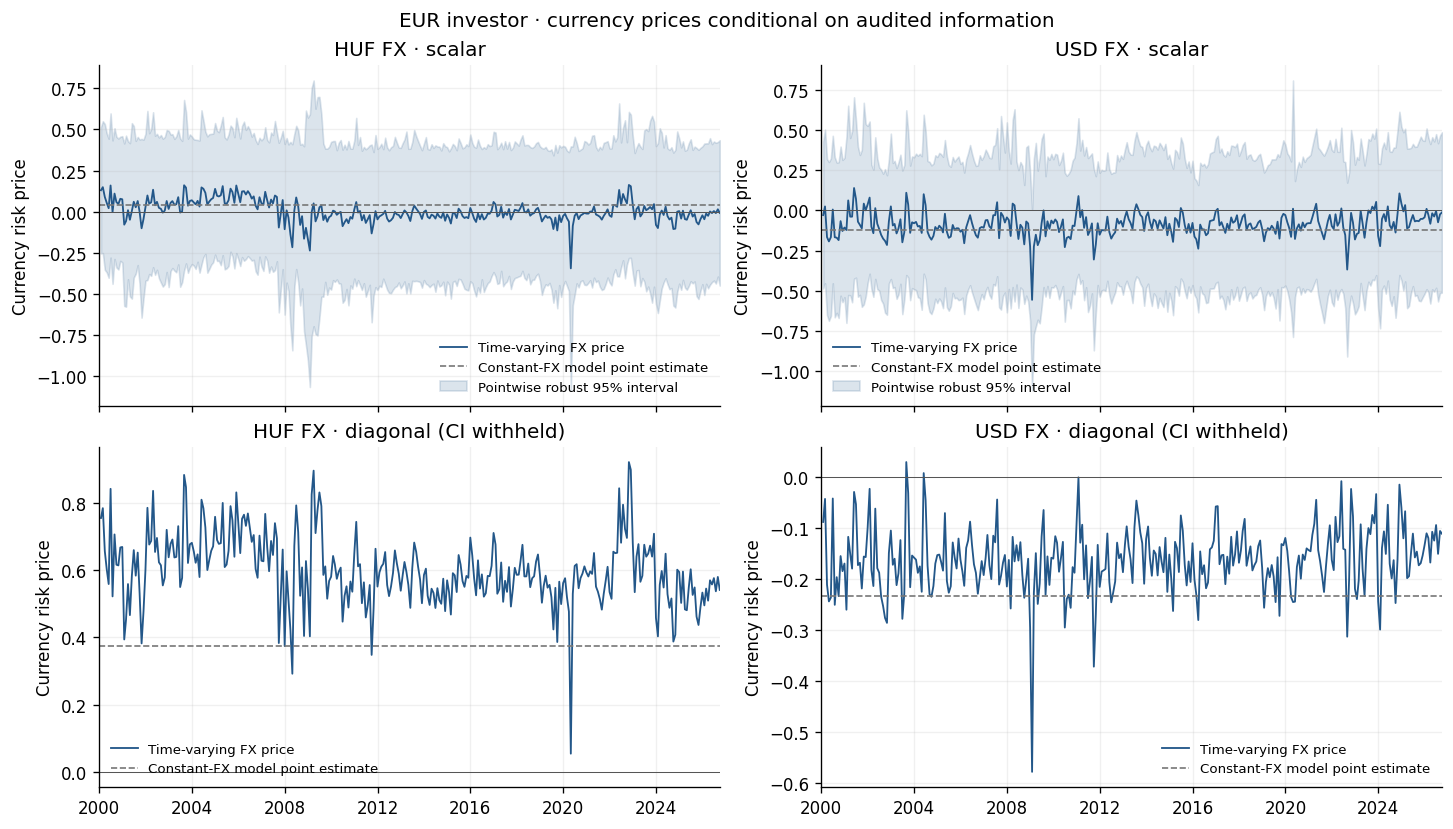

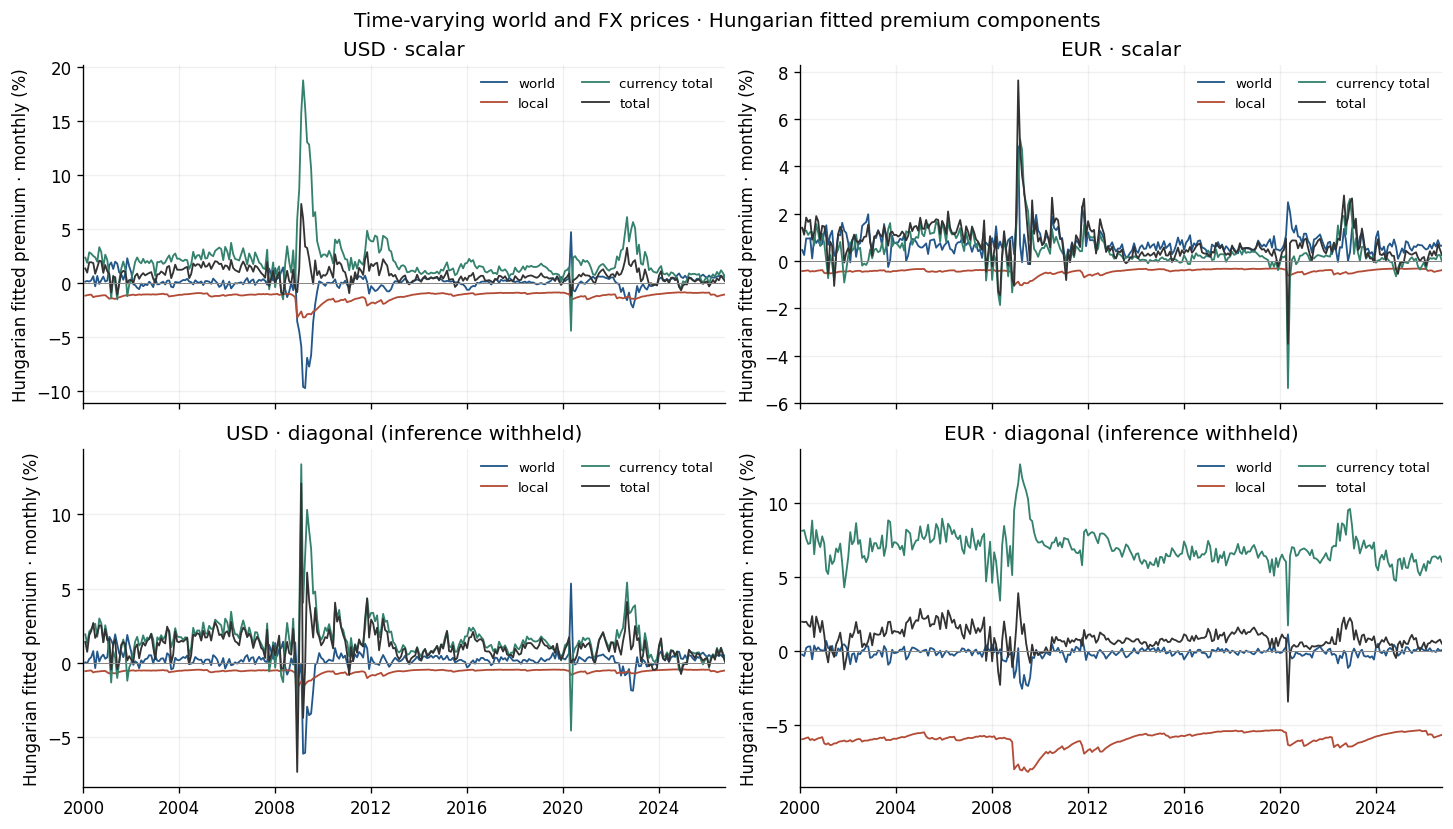

In [11]:
dates=data.index.to_timestamp("M")
for currency in ["USD","EUR"]:
    fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3.4*len(COVARIANCE_MODELS)),squeeze=False,sharex=True,layout="constrained")
    for row,covariance_model in enumerate(COVARIANCE_MODELS):
        fit=fits[f"{currency}_{covariance_model}_time_varying_fx"]
        reference=fits[f"{currency}_{covariance_model}_constant_fx"]["filter"]["fx_prices"]
        for col,label in enumerate(["H","O"]):
            ax=axes[row,col];values=fit["filter"]["fx_prices"][:,col]
            ax.plot(dates,values,color="#235789",lw=1.1,label="Time-varying FX price")
            ax.axhline(reference[0,col],color="#777777",ls="--",lw=1,label="Constant-FX model point estimate")
            if fit["inference_ready"]:
                se=fit["price_se"][label]
                ax.fill_between(dates,values-1.96*se,values+1.96*se,color="#235789",alpha=.16,label="Pointwise robust 95% interval")
            ax.axhline(0,color="#555555",lw=.6)
            ax.set(title=f"{FX_NAMES[currency][col]} FX · {covariance_model}"+(" (CI withheld)" if not fit["inference_ready"] else ""),ylabel="Currency risk price",xlim=(data.index[0].start_time,data.index[-1].end_time))
            ax.legend(frameon=False,fontsize=8)
    fig.suptitle(f"{currency} investor · currency prices conditional on audited information")
    plt.savefig(OUT/f"02_currency_prices_{currency.lower()}.png",dpi=160,bbox_inches="tight")
    plt.show();plt.close()

components={}
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3.4*len(COVARIANCE_MODELS)),squeeze=False,sharex=True,layout="constrained")
for row,covariance_model in enumerate(COVARIANCE_MODELS):
    for col,currency in enumerate(["USD","EUR"]):
        for model in ["constant_fx","time_varying_fx"]:
            fit=fits[f"{currency}_{covariance_model}_{model}"];f=fit["filter"];H,p=f["H"],f["prices"]
            frame=pd.DataFrame({"world":f["world_prices"]*H[:,2,0],"local":p[2]*H[:,2,2],
                "HUF_FX":f["fx_prices"][:,0]*H[:,2,3],"other_FX":f["fx_prices"][:,1]*H[:,2,4]},index=data.index)
            frame["currency_total"]=frame["HUF_FX"]+frame["other_FX"]
            frame["total"]=frame["world"]+frame["local"]+frame["currency_total"]
            np.testing.assert_allclose(frame["total"],f["mu"][:,2],atol=1e-10,rtol=0)
            components[f"{currency}_{covariance_model}_{model}"]=frame
            if model=="time_varying_fx":
                ax=axes[row,col]
                for name,color in [("world","#235789"),("local","#b34c36"),("currency_total","#34816d"),("total","#333333")]:
                    ax.plot(dates,frame[name],label=name.replace("_"," "),color=color,lw=1.1)
                ax.axhline(0,color="#888888",lw=.6)
                ax.set(title=f"{currency} · {covariance_model}"+(" (inference withheld)" if not fit["inference_ready"] else ""),
                       ylabel="Hungarian fitted premium · monthly (%)",xlim=(data.index[0].start_time,data.index[-1].end_time))
                ax.legend(frameon=False,ncol=2,fontsize=8)
fig.suptitle("Time-varying world and FX prices · Hungarian fitted premium components")
plt.savefig(OUT/"03_hungary_premium_components.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 9. Final comparison and reproducibility record

The main test compares constant versus varying FX prices **conditional on a time-varying world
price**. Negative AIC/BIC changes favour the extension, within the same currency, sample and
five-series likelihood. Nominal diagnostic flags locate remaining work. Passing or failing a constancy
test alone does not establish that all currency-price coefficients are zero.

In [12]:
summary_rows=[]
for currency in ["USD","EUR"]:
    for covariance_model in COVARIANCE_MODELS:
        no,yes=(fit_table.loc[(currency,covariance_model,m)] for m in ["constant_fx","time_varying_fx"])
        marginal=residual_table.loc[(currency,covariance_model,"time_varying_fx")]
        cross=cross_table.loc[(currency,covariance_model,"time_varying_fx")]
        def test_p(name):return wald_table.loc[(currency,covariance_model,"time_varying_fx",name),"robust_p_value"]
        summary_rows.append({"perspective":currency,"covariance_model":covariance_model,
            "FX_constancy_p":test_p("FX prices constant"),"HUF_constancy_p":test_p("HUF price constant"),
            "other_constancy_p":test_p("Other FX price constant"),"FX_zero_p":test_p("FX prices zero"),
            "local_information_p":test_p("Local FX information zero"),"delta_AIC":yes["AIC"]-no["AIC"],"delta_BIC":yes["BIC"]-no["BIC"],
            "mean_flags":int(marginal["LB_z_p"].lt(.05).sum()),
            "variance_flags":int((marginal["LB_z_squared_p"].lt(.05)|marginal["ARCH_LM_p"].lt(.05)).sum()),
            "cross_flags":int(cross["LB_product_p"].lt(.05).sum()),"inference_ready":bool(yes["numerical_inference_ready"])})
summary=pd.DataFrame(summary_rows).set_index(["perspective","covariance_model"]).sort_index()
inflation_export=pd.concat({"level":gap_levels.loc[data.index],"change":gap_changes.loc[data.index]},axis=1)
inflation_export.columns=[f"{a}_{b}_lag2_pp" for a,b in inflation_export.columns]
tables={"instrument_audit.csv":instrument_audit,"design_audit.csv":design_audit,"instrument_normalizers.csv":normalizers,
        "inflation_reconstruction.csv":inflation_export,"conditioning_quality_flags.csv":quality,"regime_counts.csv":regime_counts,
        "fit_summary.csv":fit_table,"price_coefficients.csv":coefficient_table,"restriction_tests.csv":wald_table,
        "starting_points.csv":starts_table,"risk_price_paths.csv":price_paths,"residual_diagnostics.csv":residual_table,
        "cross_covariance_diagnostics.csv":cross_table,"summary.csv":summary}
for name,table in tables.items():table.to_csv(OUT/name,float_format="%.17g",lineterminator="\n")
for currency,frames in feature_frames.items():
    for label,frame in frames.items():
        design=pd.DataFrame(price_designs[currency][label],index=data.index,columns=["constant"]+list(frame.columns))
        design.to_csv(OUT/f"conditioning_{currency.lower()}_{label}.csv",float_format="%.17g",lineterminator="\n")
        frame.corr().to_csv(OUT/f"correlations_{currency.lower()}_{label}.csv",float_format="%.17g",lineterminator="\n")
for key,fit in fits.items():
    np.savez(OUT/f"parameters_{key}.npz",theta=fit["theta"],robust_covariance=fit["covariance"],
             H=fit["filter"]["H"],mu=fit["filter"]["mu"],residuals=fit["filter"]["errors"])
for key,frame in components.items():frame.to_csv(OUT/f"hungary_premium_{key.lower()}.csv",float_format="%.17g",lineterminator="\n")
record={"model_version":MODEL_VERSION,"model_code_sha256":model_code_sha256,"source_snapshot":SNAPSHOT,
    "source_dataset_sha256":manifest["exports"]["dataset.csv"],"raw_ecb_sha256":fx_source_sha256,"raw_fred_sha256":fred_sha256,
    "raw_hicp_sha256":hicp_sha256,"baseline_file_sha256":baseline_hashes,"first":str(data.index[0]),"last":str(data.index[-1]),
    "observations":len(data),"instrument_specification":spec,"instrument_choice":"exploratory stationarity/persistence audit before pricing fits",
    "prices":"world and both currencies linear in separate demeaned/standardised designs; local prices constant; unrestricted signs",
    "FX_VAR_lags":FX_VAR_LAGS,"FX_means":"separate jointly estimated VAR, unchanged from notebook 06",
    "US_annual_inflation_carry_months":carry_limit,"covariance_models":COVARIANCE_MODELS,"SE_step_tolerance":SE_STEP_TOL,
    "return_unit":"monthly log percentage points","test_lags":TEST_LAGS,"packages":versions,"python":platform.python_version()}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
for name,expected in [("dataset.csv",manifest["exports"]["dataset.csv"]),("raw/ecb_fx.csv",fx_source_sha256),
                      ("raw/fred.csv",fred_sha256),("raw/eurostat_hicp.json",hicp_sha256)]:
    if hashlib.sha256((source/name).read_bytes()).hexdigest()!=expected:raise ValueError("Frozen input changed.")
display(Markdown(f"**Final summary — {len(data)} matched months; both currency prices may vary**"))
display(summary.round(4))
for (currency,covariance_model),row in summary.iterrows():
    p=row["FX_constancy_p"];text=f"{p:.3f}" if np.isfinite(p) else "withheld (bound/curvature/SE stability gate)"
    display(Markdown(f"**{currency} · {covariance_model}:** joint constant-FX-price Wald p = **{text}**; "
        f"varying minus constant FX AIC = **{row['delta_AIC']:+.2f}**, BIC = **{row['delta_BIC']:+.2f}**. "
        f"Residual flags: {int(row['mean_flags'])} mean, {int(row['variance_flags'])} variance, {int(row['cross_flags'])} covariance."))
if "scalar" in COVARIANCE_MODELS:
    main=summary.xs("scalar",level="covariance_model")
    if main["FX_constancy_p"].notna().all() and main["FX_constancy_p"].gt(.05).all():
        display(Markdown("**Main scalar reading:** neither perspective rejects constant FX prices at 5% "
            "with these conditioners. Wide individual intervals and remaining residual flags limit the conclusion; "
            "a constancy test does not establish that currency premia are zero."))
    indications=[c for c,r in main.iterrows() if .05<=r["FX_constancy_p"]<.10]
    if indications:
        display(Markdown("**Exploratory indication:** "+", ".join(indications)+
            " has a joint constancy p-value between 0.05 and 0.10. Revisit this indication in sensitivity analysis "
            "alongside the factor-specific tests, information criteria and diagnostic limitations."))
if summary["delta_AIC"].gt(0).all() and summary["delta_BIC"].gt(0).all():
    display(Markdown("**Model comparison:** both AIC and BIC favour the constant-FX-price reference "
        "in every reported comparison, with the world price remaining time-varying."))
withheld=[f"{c} · {m}" for (c,m),r in summary.iterrows() if not r["inference_ready"]]
if withheld:display(Markdown("**Inference withheld:** "+", ".join(withheld)+". Read the numerical checks in `fit_summary.csv`; affected paths are illustrative."))
display(Markdown("The inflation forms and HUF regime choice are explicit adaptations; persistence, crisis observations and "
    "the carried-US-inflation flag remain sensitivity concerns. Current local prices are still time-constant. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. The frozen dataset is unchanged."))

**Final summary — 321 matched months; both currency prices may vary**

FX_constancy_p  HUF_constancy_p  \
perspective covariance_model                                    
EUR         diagonal                     NaN              NaN   
            scalar                    0.0917           0.7904   
USD         diagonal                     NaN              NaN   
            scalar                    0.3306           0.6650   

                              other_constancy_p  FX_zero_p  \
perspective covariance_model                                 
EUR         diagonal                        NaN        NaN   
            scalar                       0.4961     0.1097   
USD         diagonal                        NaN        NaN   
            scalar                       0.8171     0.4424   

                              local_information_p  delta_AIC  delta_BIC  \
perspective covariance_model                                              
EUR         diagonal                          NaN     7.5074    41.4503   
            scalar                         0.7409     8.0963    42.0393   
USD         diagonal                          NaN     4.5029    38.4458   
            scalar                         0.7009     8.5743    42.5172   

                              mean_flags  variance_flags  cross_flags  \
perspective covariance_model                                            
EUR         diagonal                   1               1            1   
            scalar                     0               1            1   
USD         diagonal                   0               3            1   
            scalar                     0               4            2   

                              inference_ready  
perspective covariance_model                   
EUR         diagonal                    False  
            scalar                       True  
USD         diagonal                    False  
            scalar                       True

**EUR · diagonal:** joint constant-FX-price Wald p = **withheld (bound/curvature/SE stability gate)**; varying minus constant FX AIC = **+7.51**, BIC = **+41.45**. Residual flags: 1 mean, 1 variance, 1 covariance.

**EUR · scalar:** joint constant-FX-price Wald p = **0.092**; varying minus constant FX AIC = **+8.10**, BIC = **+42.04**. Residual flags: 0 mean, 1 variance, 1 covariance.

**USD · diagonal:** joint constant-FX-price Wald p = **withheld (bound/curvature/SE stability gate)**; varying minus constant FX AIC = **+4.50**, BIC = **+38.45**. Residual flags: 0 mean, 3 variance, 1 covariance.

**USD · scalar:** joint constant-FX-price Wald p = **0.331**; varying minus constant FX AIC = **+8.57**, BIC = **+42.52**. Residual flags: 0 mean, 4 variance, 2 covariance.

**Main scalar reading:** neither perspective rejects constant FX prices at 5% with these conditioners. Wide individual intervals and remaining residual flags limit the conclusion; a constancy test does not establish that currency premia are zero.

**Exploratory indication:** EUR has a joint constancy p-value between 0.05 and 0.10. Revisit this indication in sensitivity analysis alongside the factor-specific tests, information criteria and diagnostic limitations.

**Model comparison:** both AIC and BIC favour the constant-FX-price reference in every reported comparison, with the world price remaining time-varying.

**Inference withheld:** EUR · diagonal, USD · diagonal. Read the numerical checks in `fit_summary.csv`; affected paths are illustrative.

The inflation forms and HUF regime choice are explicit adaptations; persistence, crisis observations and the carried-US-inflation flag remain sensitivity concerns. Current local prices are still time-constant. Outputs: `output/07_time_varying_currency/fixed_2026-11-13/2000-01_2026-09/var6_xd7a542e8`. The frozen dataset is unchanged.